# Set up & Check

In [ ]:
%pip install -q pyspark==4.0.5

from google.colab import drive
from pathlib import Path
import os
import json
import platform
import importlib.metadata
import psutil
import pyarrow.dataset as ds
from IPython.display import display
import pandas as pd

drive.mount("/content/drive")

# Source data used to prepare the common benchmark input for both engines
BENCH_SOURCE = Path(
    "/content/drive/MyDrive/hmda/clean_spark/S1_orig_denied"
)

# Benchmark results are stored separately
BENCH_OUT = Path(
    "/content/drive/MyDrive/HMDA_Thuy/benchmark"
)
BENCH_OUT.mkdir(parents=True, exist_ok=True)

if not BENCH_SOURCE.exists():
    raise FileNotFoundError(
        "Spark S1 not found. Check the hmda shortcut and the Drive account."
    )

# Only 4 columns are needed for the benchmark workload
BENCH_COLS = [
    "state_code",
    "loan_type",
    "denied_flag",
    "loan_amount",
]

dataset = ds.dataset(
    str(BENCH_SOURCE),
    format="parquet",
    partitioning="hive",
)

missing_cols = [
    c for c in BENCH_COLS if c not in dataset.schema.names
]
if missing_cols:
    raise ValueError(f"Missing benchmark columns: {missing_cols}")

# Count rows without loading the full table into memory
n_rows = dataset.count_rows()
assert n_rows == 8_300_547, f"Unexpected row count: {n_rows:,}"

# Record the current experimental environment
environment = {
    "recorded_at_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "logical_cpu_count": os.cpu_count(),
    "ram_total_GiB": round(
        psutil.virtual_memory().total / 1024**3, 2
    ),
    "versions": {
        package: importlib.metadata.version(package)
        for package in ["pandas", "numpy", "pyarrow", "pyspark"]
    },
    "source": str(BENCH_SOURCE),
    "source_rows": n_rows,
    "columns": BENCH_COLS,
    "workload": (
        "Group by state_code and loan_type; calculate application count, "
        "denied count, denial rate and mean loan amount"
    ),
    "planned_fractions": [0.25, 0.50, 1.00],
    "measured_runs_per_case": 5,
}

with open(
    BENCH_OUT / "environment.json", "w", encoding="utf-8"
) as f:
    json.dump(environment, f, ensure_ascii=False, indent=2)

print("\nBENCHMARK PREPARATION CHECK")
print("-" * 50)
print(f"Source applications: {n_rows:,}")
print("All 4 required columns present: OK")
print("CPU logic:", environment["logical_cpu_count"])
print("Total RAM:", environment["ram_total_GiB"], "GiB")
print("\nLibrary versions:")
display(pd.Series(environment["versions"], name="version").to_frame())

print("\nEnvironment information saved:")
print("My Drive → HMDA_Thuy → benchmark → environment.json")
print("\nOK — ready to prepare the common data samples.")

Mounted at /content/drive

BENCHMARK PREPARATION CHECK
--------------------------------------------------
Source applications: 8,300,547
All 4 required columns present: OK
CPU logic: 2
Total RAM: 12.67 GiB

Library versions:


,version
pandas,2.2.3
numpy,2.4.6
pyarrow,23.0.1
pyspark,4.0.5



Environment information saved:
My Drive → HMDA_Thuy → benchmark → environment.json

OK — ready to prepare the common data samples.


In [ ]:
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import pyarrow.dataset as ds
from pathlib import Path
import shutil
import json
import gc
from IPython.display import display

# Local Colab files used during the benchmark
LOCAL_INPUTS = Path("/content/hmda_benchmark_inputs")
LOCAL_INPUTS.mkdir(parents=True, exist_ok=True)

# Drive copy for reuse if the Colab session disconnects
DRIVE_INPUTS = BENCH_OUT / "inputs"
DRIVE_INPUTS.mkdir(parents=True, exist_ok=True)

# Keep the source file order fixed so that sampling is reproducible
source_files = sorted(
    str(p) for p in BENCH_SOURCE.rglob("*.parquet")
)

source_schema = ds.dataset(
    str(BENCH_SOURCE),
    format="parquet",
    partitioning="hive",
).schema

source = ds.dataset(
    source_files,
    format="parquet",
    schema=source_schema,
    partitioning="hive",
    partition_base_dir=str(BENCH_SOURCE),
)

total = source.count_rows()
assert total == 8_300_547

sizes = {
    "25pct": total // 4,
    "50pct": total // 2,
    "100pct": total,
}

# Each row position receives a unique random order.
# The same order is used to create nested samples.
rng = np.random.default_rng(42)
random_order = rng.permutation(total)

# Common data types, identical for both engines
output_schema = pa.schema([
    ("state_code", pa.string()),
    ("loan_type", pa.string()),
    ("denied_flag", pa.int8()),
    ("loan_amount", pa.float64()),
])

writers = {}
written = {name: 0 for name in sizes}

try:
    for name in sizes:
        writers[name] = pq.ParquetWriter(
            str(LOCAL_INPUTS / f"S1_{name}.partial.parquet"),
            output_schema,
            compression="snappy",
        )

    scanner = source.scanner(
        columns=BENCH_COLS,
        batch_size=250_000,
        use_threads=False,
    )

    offset = 0
    print("Creating the three common datasets...", flush=True)

    for batch_number, batch in enumerate(scanner.to_batches(), start=1):
        table = pa.Table.from_batches([batch]).cast(output_schema)
        length = len(table)
        ranks = random_order[offset:offset + length]

        for name, target_size in sizes.items():
            if name == "100pct":
                selected = table
            else:
                selected = table.filter(
                    pa.array(ranks < target_size)
                )

            if len(selected):
                writers[name].write_table(selected)
                written[name] += len(selected)

        offset += length

        if batch_number % 8 == 0 or offset == total:
            print(f"Processed {offset:,}/{total:,} applications", flush=True)

    assert offset == total

finally:
    for writer in writers.values():
        writer.close()

# Check and finalise the files
manifest_rows = []

for name, expected_rows in sizes.items():
    assert written[name] == expected_rows

    partial_path = LOCAL_INPUTS / f"S1_{name}.partial.parquet"
    final_path = LOCAL_INPUTS / f"S1_{name}.parquet"

    actual_rows = pq.ParquetFile(partial_path).metadata.num_rows
    assert actual_rows == expected_rows

    partial_path.replace(final_path)

    # Save a copy on Drive
    drive_path = DRIVE_INPUTS / final_path.name
    shutil.copy2(final_path, drive_path)

    assert (
        pq.ParquetFile(drive_path).metadata.num_rows == expected_rows
    )

    manifest_rows.append({
        "sample": name,
        "rows": actual_rows,
        "actual_pct_of_S1": actual_rows / total * 100,
        "file_size_MiB": final_path.stat().st_size / 1024**2,
        "local_path": str(final_path),
        "drive_path": str(drive_path),
    })

del random_order
gc.collect()

benchmark_manifest = pd.DataFrame(manifest_rows)

benchmark_manifest.to_csv(
    BENCH_OUT / "input_manifest.csv",
    index=False,
    encoding="utf-8-sig",
)

sampling_info = {
    "seed": 42,
    "method": "Uniform random sampling without replacement; nested samples",
    "source": str(BENCH_SOURCE),
    "source_files_sorted": source_files,
    "columns": BENCH_COLS,
    "rows": sizes,
    "timing_note": "Sampling and file preparation excluded from benchmark",
}

with open(
    BENCH_OUT / "sampling_info.json", "w", encoding="utf-8"
) as f:
    json.dump(sampling_info, f, ensure_ascii=False, indent=2)

print("\nINPUT PREPARATION RESULTS")
display(
    benchmark_manifest[
        ["sample", "rows", "actual_pct_of_S1", "file_size_MiB"]
    ].round(2)
)

print("\nOK — the three datasets were checked and saved.")
print("Saved copy: My Drive → HMDA_Thuy → benchmark → inputs")
print("Timing has not started yet.")

Creating the three common datasets...
Processed 1,333,762/8,300,547 applications
Processed 2,466,680/8,300,547 applications
Processed 3,182,188/8,300,547 applications
Processed 4,159,246/8,300,547 applications
Processed 4,866,485/8,300,547 applications
Processed 5,925,937/8,300,547 applications
Processed 6,804,366/8,300,547 applications
Processed 8,044,018/8,300,547 applications
Processed 8,300,547/8,300,547 applications

INPUT PREPARATION RESULTS


,sample,rows,actual_pct_of_S1,file_size_MiB
0,25pct,2075136,25.0,2.74
1,50pct,4150273,50.0,5.46
2,100pct,8300547,100.0,11.04



OK — the three datasets were checked and saved.
Saved copy: My Drive → HMDA_Thuy → benchmark → inputs
Timing has not started yet.


In [ ]:
import pandas as pd
import numpy as np
import pyarrow.parquet as pq
from pyspark.sql import SparkSession, functions as F
from pathlib import Path
import json
import time
import gc
from IPython.display import display

# 1. Start Spark before the benchmark timing
start_setup = time.perf_counter()

spark = (
    SparkSession.builder
    .appName("HMDA_Thuy_Benchmark")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.catalog.clearCache()

setup_seconds = time.perf_counter() - start_setup

KEYS = ["state_code", "loan_type"]

# 2. Pandas version
def workload_pandas(path):
    df = pq.read_table(
        str(path), columns=BENCH_COLS
    ).to_pandas(strings_to_categorical=True)

    # Keep applications with missing group information in a Missing group
    for column in KEYS:
        if isinstance(df[column].dtype, pd.CategoricalDtype):
            if "Missing" not in df[column].cat.categories:
                df[column] = df[column].cat.add_categories(["Missing"])
        df[column] = df[column].fillna("Missing")

    result = (
        df.groupby(KEYS, observed=True, sort=False)
        .agg(
            applications=("denied_flag", "size"),
            denied=("denied_flag", "sum"),
            mean_loan_amount=("loan_amount", "mean"),
        )
        .reset_index()
    )
    result["denial_rate_pct"] = (
        result["denied"] / result["applications"] * 100
    )
    return result


# 3. Spark version
def workload_spark(path):
    df = spark.read.parquet(str(path)).select(*BENCH_COLS)

    for column in KEYS:
        df = df.withColumn(
            column, F.coalesce(F.col(column), F.lit("Missing"))
        )

    amount = F.col("loan_amount")
    df = df.withColumn(
        "loan_amount",
        F.when(amount.isNull() | F.isnan(amount), F.lit(None))
         .otherwise(amount)
    )

    result = (
        df.groupBy(*KEYS)
        .agg(
            F.count("*").alias("applications"),
            F.sum("denied_flag").alias("denied"),
            F.avg("loan_amount").alias("mean_loan_amount"),
        )
        .withColumn(
            "denial_rate_pct",
            F.col("denied") / F.col("applications") * 100
        )
    )

    # Force Spark to execute and return the small aggregated table to Python
    return result.toPandas()


# 4. Check the results on all three samples
RESULTS_OUT = BENCH_OUT / "workload_results"
RESULTS_OUT.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(BENCH_OUT / "input_manifest.csv")
checks = []

for sample in manifest.itertuples(index=False):
    path = Path(sample.local_path)

    if not path.exists():
        raise FileNotFoundError(
            f"Local file not found: {path}. "
            "Send this error to restore the file from Drive."
        )

    print(f"Checking sample {sample.sample}...", flush=True)

    pandas_result = workload_pandas(path)
    spark_result = workload_spark(path)

    compared = pandas_result.merge(
        spark_result,
        on=KEYS,
        how="outer",
        suffixes=("_pandas", "_spark"),
        indicator=True,
        validate="one_to_one",
    )

    groups_match = compared["_merge"].eq("both").all()

    count_match = all(
        compared[f"{c}_pandas"].eq(compared[f"{c}_spark"]).all()
        for c in ["applications", "denied"]
    )

    mean_match = np.isclose(
        compared["mean_loan_amount_pandas"],
        compared["mean_loan_amount_spark"],
        atol=1e-6, rtol=1e-10, equal_nan=True,
    ).all()

    rate_match = np.isclose(
        compared["denial_rate_pct_pandas"],
        compared["denial_rate_pct_spark"],
        atol=1e-9, rtol=0, equal_nan=True,
    ).all()

    rows_match = (
        pandas_result["applications"].sum() == sample.rows
        and spark_result["applications"].sum() == sample.rows
    )

    checks.append({
        "sample": sample.sample,
        "input_rows": sample.rows,
        "groups": len(pandas_result),
        "groups_match": bool(groups_match),
        "counts_match": bool(count_match),
        "mean_match": bool(mean_match),
        "rate_match": bool(rate_match),
        "rows_match": bool(rows_match),
        "pass": bool(
            groups_match and count_match and mean_match
            and rate_match and rows_match
        ),
    })

    pandas_result.to_csv(
        RESULTS_OUT / f"{sample.sample}_pandas.csv", index=False
    )
    spark_result.to_csv(
        RESULTS_OUT / f"{sample.sample}_spark.csv", index=False
    )

    gc.collect()

benchmark_correctness = pd.DataFrame(checks)
benchmark_correctness.to_csv(
    BENCH_OUT / "workload_correctness.csv", index=False
)

# 5. Record the agreed timing scope
measurement_plan = {
    "timed_scope": (
        "Read local Parquet, normalize missing values, aggregate, "
        "and return the small result as a Pandas DataFrame"
    ),
    "excluded": [
        "Installation", "Spark startup", "Sampling",
        "Drive copying", "Displaying results", "Writing result files"
    ],
    "spark_master": spark.sparkContext.master,
    "spark_version": spark.version,
    "spark_shuffle_partitions": spark.conf.get(
        "spark.sql.shuffle.partitions"
    ),
    "spark_setup_seconds_excluded": setup_seconds,
    "spark_cache": "No explicit cache or persist",
    "filesystem_cache": (
        "OS filesystem cache is not cleared; this is not a cold-disk test"
    ),
    "runs_per_case": 5,
}

with open(
    BENCH_OUT / "measurement_plan.json", "w", encoding="utf-8"
) as f:
    json.dump(measurement_plan, f, ensure_ascii=False, indent=2)

print("\nWORKLOAD CHECK RESULTS")
display(benchmark_correctness)

if benchmark_correctness["pass"].all():
    print("\nPASS — both engines produce equivalent results on all three samples.")
    print("Ready for timing.")
else:
    print("\nDIFFERENCES FOUND — resolve before timing.")

Checking sample 25pct...
Checking sample 50pct...
Checking sample 100pct...

WORKLOAD CHECK RESULTS


,sample,input_rows,groups,groups_match,counts_match,mean_match,rate_match,rows_match,pass
0,25pct,2075136,216,True,True,True,True,True,True
1,50pct,4150273,216,True,True,True,True,True,True
2,100pct,8300547,218,True,True,True,True,True,True



PASS — both engines produce equivalent results on all three samples.
Ready for timing.


# Time Monitoring

In [ ]:
import time
import gc
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

assert benchmark_correctness["pass"].all(), (
    "The workload did not pass the correctness check."
)

# Each run of this block creates its own result set and does not overwrite earlier runs
RUN_ID = pd.Timestamp.now(tz="UTC").strftime("%Y%m%dT%H%M%S%fZ")
RUN_OUT = BENCH_OUT / f"run_{RUN_ID}"
RUN_OUT.mkdir(parents=True, exist_ok=False)

functions = {
    "Pandas": workload_pandas,
    "Spark": workload_spark,
}

samples = {
    row.sample: {
        "path": Path(row.local_path),
        "rows": int(row.rows),
    }
    for row in manifest.itertuples(index=False)
}

# Read the small reference table before timing
references = {
    name: pd.read_csv(
        RESULTS_OUT / f"{name}_pandas.csv",
        dtype={
            "state_code": "string",
            "loan_type": "string",
        },
    )
    for name in samples
}

def validate_result(result, reference, expected_rows):
    merged = reference.merge(
        result,
        on=KEYS,
        how="outer",
        suffixes=("_ref", "_run"),
        indicator=True,
        validate="one_to_one",
    )

    return bool(
        merged["_merge"].eq("both").all()
        and result["applications"].sum() == expected_rows
        and all(
            merged[f"{c}_ref"].eq(merged[f"{c}_run"]).all()
            for c in ["applications", "denied"]
        )
        and np.isclose(
            merged["mean_loan_amount_ref"],
            merged["mean_loan_amount_run"],
            atol=1e-6, rtol=1e-10, equal_nan=True,
        ).all()
        and np.isclose(
            merged["denial_rate_pct_ref"],
            merged["denial_rate_pct_run"],
            atol=1e-9, rtol=0, equal_nan=True,
        ).all()
    )

# Build the run schedule: 5 runs per sample for each engine
rng = np.random.default_rng(2026)
sample_names = list(samples)
schedule = []

for repeat in range(1, 6):
    sample_order = list(rng.permutation(sample_names))

    for name in sample_order:
        sample_index = sample_names.index(name)

        # Alternate which engine runs first across repetitions
        engines = (
            ["Pandas", "Spark"]
            if (repeat + sample_index) % 2 == 0
            else ["Spark", "Pandas"]
        )

        for engine in engines:
            schedule.append({
                "sample": name,
                "repeat": repeat,
                "engine": engine,
            })

pd.DataFrame(schedule).to_csv(
    RUN_OUT / "schedule.csv", index=False
)

# The earlier checks already started and warmed up both engines.
# The OS cache is not cleared; Spark cache/persist is not used.
spark.catalog.clearCache()

records = []

for position, task in enumerate(schedule, start=1):
    name = task["sample"]
    engine = task["engine"]
    path = samples[name]["path"]
    expected_rows = samples[name]["rows"]

    if not path.exists():
        raise FileNotFoundError(f"Input not found: {path}")

    gc.collect()  # Outside the timed section

    print(
        f"[{position}/30] {name} | {engine} | run {task['repeat']}",
        flush=True,
    )

    # ===== START TIMING =====
    started = time.perf_counter()
    result = functions[engine](path)
    seconds = time.perf_counter() - started
    # ===== END TIMING =====

    # Checking and file writing are outside the timed section
    valid = validate_result(
        result, references[name], expected_rows
    )

    records.append({
        "execution_order": position,
        "sample": name,
        "rows": expected_rows,
        "engine": engine,
        "repeat": task["repeat"],
        "seconds": seconds,
        "result_valid": valid,
    })

    pd.DataFrame(records).to_csv(
        RUN_OUT / "benchmark_runs.csv", index=False
    )

    print(f"    {seconds:.3f} s | results match: {valid}", flush=True)

    del result

    if not valid:
        raise ValueError(
            "Run results do not match. Progress saved; send the output for review."
        )

benchmark_runs = pd.DataFrame(records)

# Check that every sample × engine combination has 5 runs
run_counts = benchmark_runs.groupby(["sample", "engine"]).size()
assert len(run_counts) == 6 and run_counts.eq(5).all()
assert benchmark_runs["result_valid"].all()

# Summarise median, min, max
timing_stats = (
    benchmark_runs.groupby(["sample", "rows", "engine"])["seconds"]
    .agg(median_seconds="median", min_seconds="min", max_seconds="max")
    .reset_index()
)

benchmark_summary = timing_stats.pivot(
    index=["sample", "rows"],
    columns="engine",
    values="median_seconds",
).reset_index()

benchmark_summary.columns.name = None
benchmark_summary = benchmark_summary.rename(
    columns={"Pandas": "pandas_median_s", "Spark": "spark_median_s"}
)

benchmark_summary["speedup_pandas_over_spark"] = (
    benchmark_summary["pandas_median_s"]
    / benchmark_summary["spark_median_s"]
)

benchmark_summary["faster"] = np.where(
    benchmark_summary["pandas_median_s"]
    < benchmark_summary["spark_median_s"],
    "Pandas",
    np.where(
        benchmark_summary["pandas_median_s"]
        > benchmark_summary["spark_median_s"],
        "Spark",
        "Equal",
    ),
)

benchmark_summary = benchmark_summary.sort_values("rows")

timing_stats.to_csv(RUN_OUT / "timing_stats.csv", index=False)
benchmark_summary.to_csv(
    RUN_OUT / "benchmark_summary.csv", index=False
)

with open(RUN_OUT / "measurement_plan.json", "w", encoding="utf-8") as f:
    json.dump(measurement_plan, f, ensure_ascii=False, indent=2)

print("\nBENCHMARK RESULTS — MEDIAN OF 5 RUNS")
display(benchmark_summary.round(3))

print("\nCOMPLETE — all 30 runs finished and all results match.")
print("Results saved to:", RUN_OUT)

[1/30] 50pct | Pandas | run 1
    1.682 s | results match: True
[2/30] 50pct | Spark | run 1
    5.110 s | results match: True
[3/30] 25pct | Spark | run 1
    4.401 s | results match: True
[4/30] 25pct | Pandas | run 1
    0.627 s | results match: True
[5/30] 100pct | Spark | run 1
    2.889 s | results match: True
[6/30] 100pct | Pandas | run 1
    2.144 s | results match: True
[7/30] 25pct | Pandas | run 2
    0.442 s | results match: True
[8/30] 25pct | Spark | run 2
    1.387 s | results match: True
[9/30] 50pct | Spark | run 2
    2.086 s | results match: True
[10/30] 50pct | Pandas | run 2
    1.428 s | results match: True
[11/30] 100pct | Pandas | run 2
    3.187 s | results match: True
[12/30] 100pct | Spark | run 2
    2.526 s | results match: True
[13/30] 25pct | Spark | run 3
    1.298 s | results match: True
[14/30] 25pct | Pandas | run 3
    0.564 s | results match: True
[15/30] 50pct | Pandas | run 3
    0.898 s | results match: True
[16/30] 50pct | Spark | run 3
    1.4

,sample,rows,pandas_median_s,spark_median_s,speedup_pandas_over_spark,faster
1,25pct,2075136,0.549,1.354,0.405,Pandas
2,50pct,4150273,1.039,2.421,0.429,Pandas
0,100pct,8300547,2.144,2.725,0.787,Pandas



COMPLETE — all 30 runs finished and all results match.
Results saved to: /content/drive/MyDrive/HMDA_Thuy/benchmark/run_20261118T142526405847Z


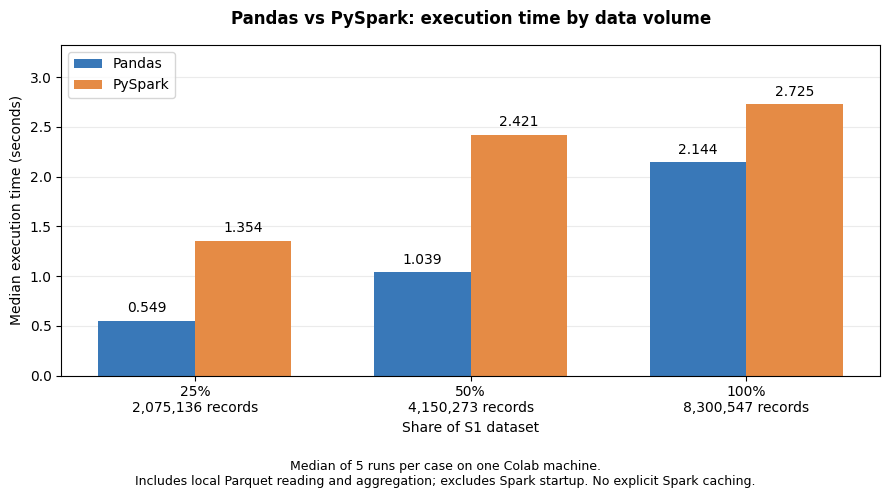

Figure saved to: /content/drive/MyDrive/HMDA_Thuy/benchmark/run_20261118T142526405847Z/benchmark_execution_time.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Use the unrounded results of the successful run
plot_data = benchmark_summary.sort_values("rows").copy()
x = np.arange(len(plot_data))
width = 0.35

fig, ax = plt.subplots(figsize=(9, 5))

pandas_bars = ax.bar(
    x - width / 2,
    plot_data["pandas_median_s"],
    width,
    label="Pandas",
    color="#3978B8",
)

spark_bars = ax.bar(
    x + width / 2,
    plot_data["spark_median_s"],
    width,
    label="PySpark",
    color="#E58B45",
)

for bars in [pandas_bars, spark_bars]:
    ax.bar_label(bars, fmt="%.3f", padding=4, fontsize=10)

labels = [
    f"{pct}\n{rows:,} records"
    for pct, rows in zip(
        ["25%", "50%", "100%"], plot_data["rows"]
    )
]

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_xlabel("Share of S1 dataset")
ax.set_ylabel("Median execution time (seconds)")
ax.set_title(
    "Pandas vs PySpark: execution time by data volume",
    fontweight="bold",
    pad=15,
)

ax.set_ylim(
    0,
    max(
        plot_data["pandas_median_s"].max(),
        plot_data["spark_median_s"].max(),
    ) * 1.22,
)

ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)
ax.legend()

fig.text(
    0.5, 0.02,
    "Median of 5 runs per case on one Colab machine.\n"
    "Includes local Parquet reading and aggregation; "
    "excludes Spark startup. No explicit Spark caching.",
    ha="center",
    fontsize=9,
)

fig.tight_layout(rect=[0, 0.09, 1, 1])

figure_path = RUN_OUT / "benchmark_execution_time.png"
fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight",
    facecolor="white",
)

plt.show()

print("Figure saved to:", figure_path)

# Report

The performance experiment compared Pandas and PySpark on a common workload: grouping S1 applications by state and loan type to calculate application counts, denial counts, denial rates and mean loan amounts. Both implementations processed identical Parquet inputs containing 25%, 50% and 100% of S1, corresponding to 2,075,136, 4,150,273 and 8,300,547 records. Each case was measured five times, with execution order varied across repetitions. All 30 measured runs passed the result-equivalence checks.

Pandas was faster at every tested volume. Median execution times were 0.549, 1.039 and 2.144 seconds for Pandas, compared with 1.354, 2.421 and 2.725 seconds for PySpark. Pandas was approximately 2.47, 2.33 and 1.27 times faster, respectively. Its execution time increased approximately in proportion to record count, while the relative performance gap narrowed at the largest volume. However, these measurements do not establish a crossover point at which Spark would become faster.

The results support Pandas as the faster option for this specific workload and environment. Spark’s execution and coordination overhead may help explain its slower performance, although this experiment did not isolate individual sources of overhead. Timings included local Parquet reading, missing-value normalization, aggregation and returning the small result table, while installation, Spark startup, sampling, file copying and result validation were excluded. Both tools ran on one Colab machine without explicit Spark caching; operating-system filesystem caching was not cleared. The experiment therefore evaluates repeated local execution rather than cold-disk performance or a multi-machine Spark cluster, and its conclusions should not be generalized to other workloads or larger datasets.